# Training a CellPose network

The notebook uses a CUDA GPU when available and falls back to CPU otherwise.

Run one seeded optimizer step without downloading data or weights.
This is a minimal starting point for a plain PyTorch training loop, not a training
recipe or a claim about accuracy. There are two synthetic objects and one foreground
class. Background is type 0; both instances have type 1. Instance IDs are preserved
for flow-target generation. Images are float32 BCHW in [0, 1]; class targets are
int64 BHW and flow targets are float32 B2HW.

For real data, `TrainDatasetFolder` reads paired image and `.mat` files with `inst`
and `type` arrays. `TrainDatasetH5` is the HDF5 alternative and additionally needs
PyTables. Both training datasets require Albumentations and aligned image/mask
transforms plus `ApplyEach([CellposeTransform()], as_list=True)` for flow targets.
Folder pairs use sorted file order: verify identifiers, shapes and class mapping.
After geometric augmentation, verify that the flow directions still match the
transformed objects. Split patients/slides before making patches; never use these
duplicate smoke samples as a real validation split.


## Setup


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from skimage.color import label2rgb

from cellseg_models_pytorch.models.cellpose.cellpose_unet import cellpose_nuclei
from cellseg_models_pytorch.transforms.functional.cellpose import gen_flow_maps

# Fix the seed so the small demonstration can be repeated.
torch.manual_seed(0)
torch.set_num_threads(2)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")

Device: cuda


## Prepare the example data


In [2]:
# Give each example object its own instance label.
rows, cols = np.mgrid[:64, :64]
instances = np.zeros((64, 64), dtype=np.int32)
instances[(rows - 24) ** 2 + (cols - 24) ** 2 < 8**2] = 1
instances[(rows - 44) ** 2 + (cols - 44) ** 2 < 6**2] = 2

# Repeated RGB channels and samples keep this demonstration small.
image = np.repeat((instances > 0)[..., None], 3, axis=2).astype(np.float32)
images = torch.from_numpy(image.transpose(2, 0, 1)).unsqueeze(0).repeat(2, 1, 1, 1)

# Both objects share a class, even though their instance labels differ.
class_targets = (
    torch.from_numpy((instances > 0).astype(np.int64)).unsqueeze(0).repeat(2, 1, 1)
)

# Flows point toward each object's centre and are a separate training target.
flow_array = gen_flow_maps(instances).astype(np.float32)
flow_targets = torch.from_numpy(flow_array).unsqueeze(0).repeat(2, 1, 1, 1)

## Create the network


In [3]:
model = cellpose_nuclei(2, enc_name="resnet18", enc_pretrain=False).to(device)

The raw `cellpose_nuclei` network supports autograd. Its `nuc` output carries
`type_map` class logits and `aux_map` vertical/horizontal flows. This example combines
ordinary cross entropy and flow MSE equally. The library also provides configurable
loss components; select weighting and metrics for your dataset rather than treating
this one-step example as a scientifically calibrated recipe.


In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

model.train()

optimizer.zero_grad(set_to_none=True)
prediction = model(images.to(device))["nuc"]

# Learn the class labels and the flows together.
classification_loss = F.cross_entropy(prediction.type_map, class_targets.to(device))
flow_loss = F.mse_loss(prediction.aux_map, flow_targets.to(device))
loss = classification_loss + flow_loss

# Backpropagation computes gradients; the optimizer updates the weights.
loss.backward()
optimizer.step()

print("Training loss:", float(loss.detach()))

Training loss: 3.404592990875244


In [5]:
# Evaluate without updating weights or tracking gradients.
model.eval()
with torch.inference_mode():
    output = model(images.to(device))["nuc"]
    validation_loss = F.cross_entropy(output.type_map, class_targets.to(device))

print("Evaluation loss (same synthetic input):", float(validation_loss))

Evaluation loss (same synthetic input): 0.45195814967155457


For a real run, iterate separate train/validation loaders over multiple epochs,
use instance reconstruction and instance metrics for validation, and save resumable
state as in the fine-tuning example. Choose device/precision explicitly. Mixed precision,
data augmentation and full-dataset training are not validated by this smoke run.


## View the result

Compare the example image and its labelled objects with the predicted classes.
Each colour represents a label. The prediction comes from only a tiny demonstration
run; it is not evidence of segmentation quality.

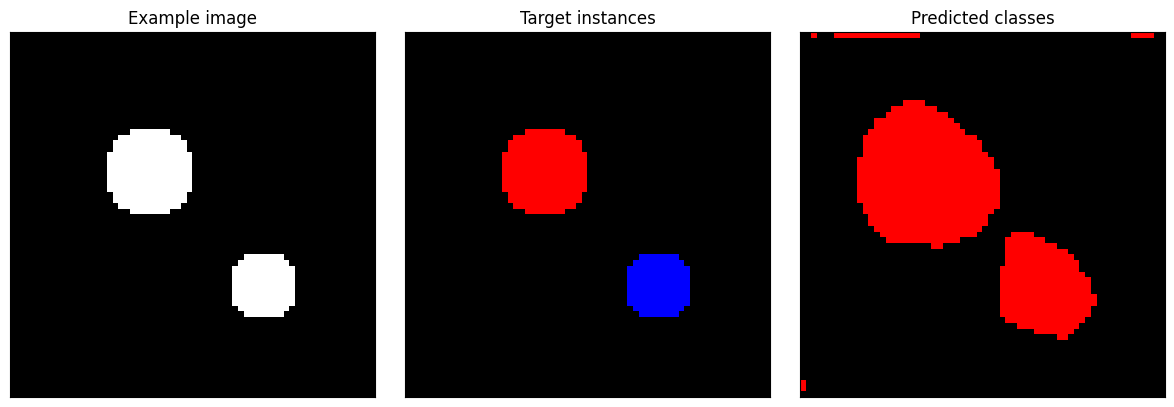

In [6]:
# Move only the displayed class map to CPU for plotting.
predicted_classes = output.type_map.argmax(dim=1)[0].detach().cpu().numpy()
instance_colors = label2rgb(instances, bg_label=0)
class_colors = label2rgb(predicted_classes, bg_label=0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image)
axes[0].set(title="Example image", xticks=[], yticks=[])

axes[1].imshow(instance_colors)
axes[1].set(title="Target instances", xticks=[], yticks=[])

axes[2].imshow(class_colors)
axes[2].set(title="Predicted classes", xticks=[], yticks=[])

fig.tight_layout()
plt.show()